Cell 1 – Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

Cell 2 – Upload dataset

In [2]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("Unemployment in India.csv")

df.head()

Saving Unemployment in India.csv to Unemployment in India (1).csv


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


Cell 3 – Data inspection

In [3]:
df.columns = df.columns.str.strip()

print("Shape:", df.shape)
print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Shape: (768, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    object 
 1   Date                                     740 non-null    object 
 2   Frequency                                740 non-null    object 
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB

Missing Values:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployme

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


Cell 4 – Data cleaning

In [4]:
df = df.dropna().copy()

df["Date"] = pd.to_datetime(
    df["Date"].str.strip(),
    dayfirst=True,
    errors="coerce"
)

df = df.dropna(subset=["Date"])

df = df.sort_values("Date")

print(df.dtypes)
print("Cleaned Shape:", df.shape)

Region                                             object
Date                                       datetime64[ns]
Frequency                                          object
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                               object
dtype: object
Cleaned Shape: (740, 7)


Cell 5 – Region-wise average unemployment

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64


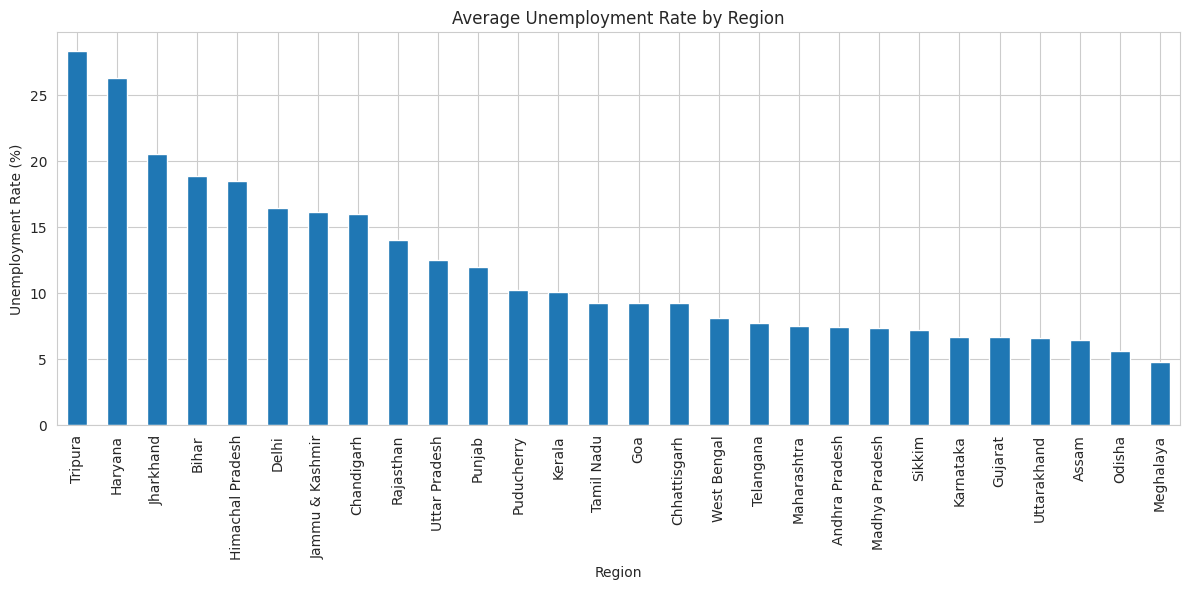

In [5]:
region_avg = df.groupby("Region")[
    "Estimated Unemployment Rate (%)"
].mean().sort_values(ascending=False)

print(region_avg)

plt.figure(figsize=(12,6))
region_avg.plot(kind="bar")
plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Cell 6 – Month-wise unemployment trend

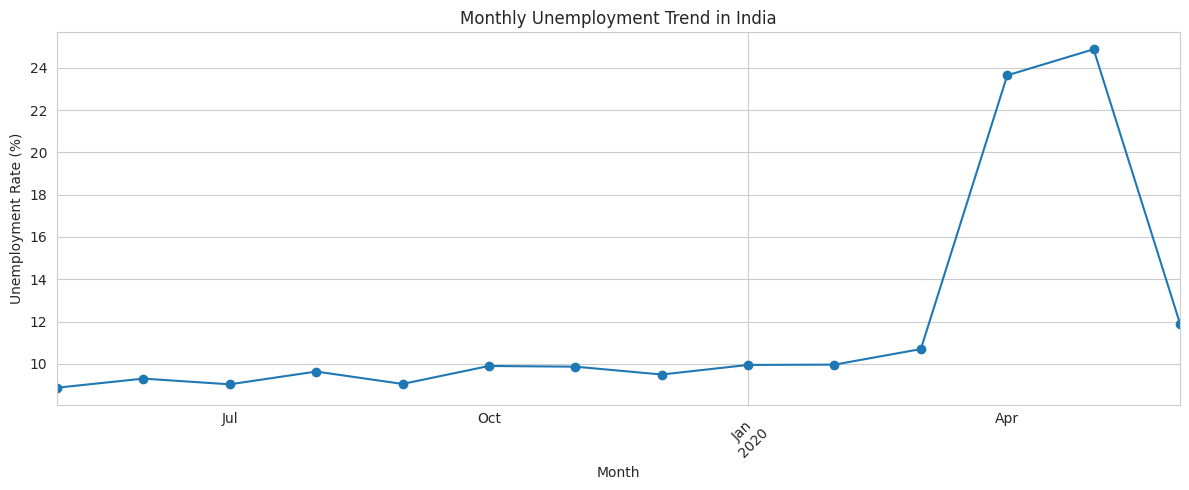

In [6]:
df["Month"] = df["Date"].dt.to_period("M")

monthly = df.groupby("Month")[
    "Estimated Unemployment Rate (%)"
].mean()

plt.figure(figsize=(12,5))
monthly.plot(marker="o")
plt.title("Monthly Unemployment Trend in India")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Cell 7 – Top 3 states trend

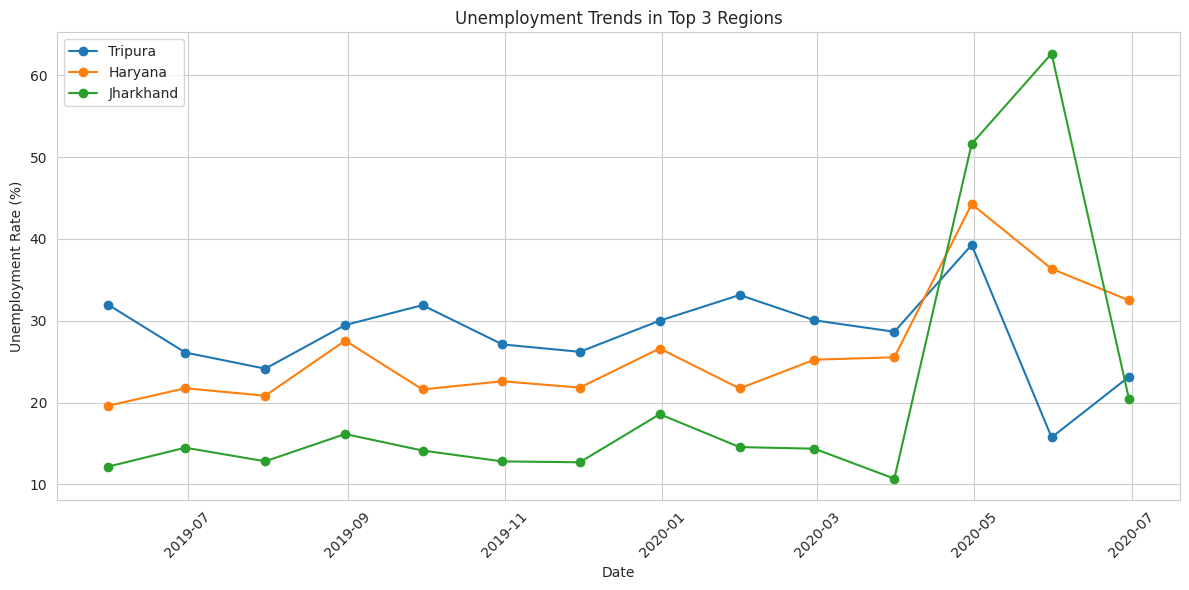

In [7]:
top3 = region_avg.head(3).index

plt.figure(figsize=(12,6))

for state in top3:
    state_data = df[df["Region"] == state]
    trend = state_data.groupby("Date")[
        "Estimated Unemployment Rate (%)"
    ].mean()

    plt.plot(trend.index, trend.values, marker="o", label=state)

plt.title("Unemployment Trends in Top 3 Regions")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Cell 8 – Top 10 states

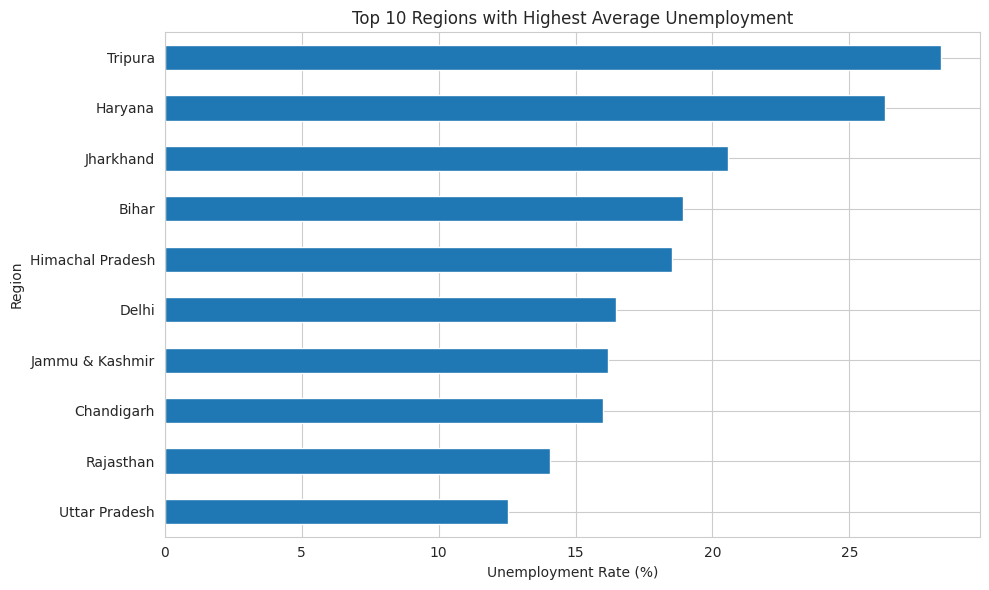

In [8]:
top10 = region_avg.head(10)

plt.figure(figsize=(10,6))
top10.sort_values().plot(kind="barh")
plt.title("Top 10 Regions with Highest Average Unemployment")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

Cell 9 – Correlation heatmap

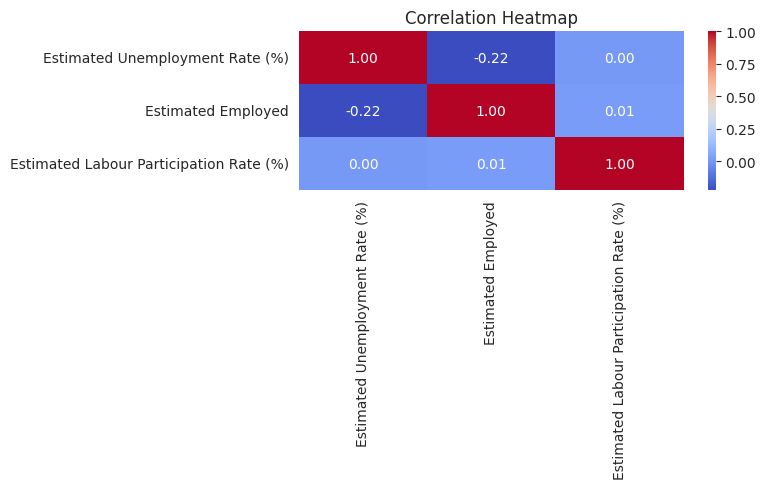

In [9]:
columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation = df[columns].corr()

plt.figure(figsize=(8,5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Cell 10 – Pre-COVID vs Post-COVID

Pre-COVID Average: 9.51 %
Post-COVID Average: 17.77 %


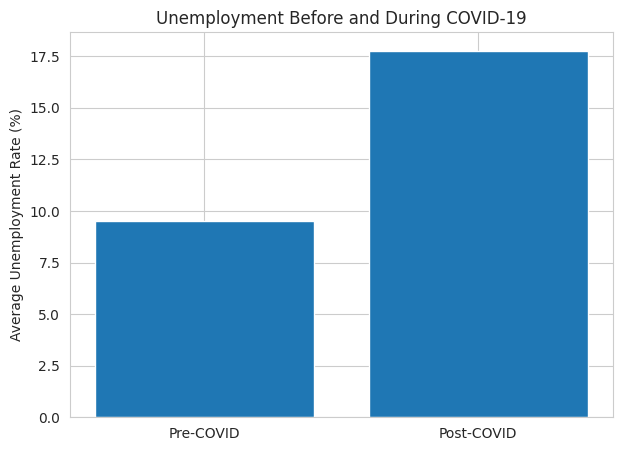

In [10]:
pre_covid = df[df["Date"] < "2020-03-01"]
post_covid = df[df["Date"] >= "2020-03-01"]

pre_mean = pre_covid[
    "Estimated Unemployment Rate (%)"
].mean()

post_mean = post_covid[
    "Estimated Unemployment Rate (%)"
].mean()

print("Pre-COVID Average:", round(pre_mean, 2), "%")
print("Post-COVID Average:", round(post_mean, 2), "%")

plt.figure(figsize=(7,5))
plt.bar(
    ["Pre-COVID", "Post-COVID"],
    [pre_mean, post_mean]
)
plt.title("Unemployment Before and During COVID-19")
plt.ylabel("Average Unemployment Rate (%)")
plt.show()

Cell 11 – Final observations

In [11]:
print("Highest unemployment region:", region_avg.index[0])
print("Highest average rate:", round(region_avg.iloc[0], 2), "%")
print("Pre-COVID average:", round(pre_mean, 2), "%")
print("Post-COVID average:", round(post_mean, 2), "%")

if post_mean > pre_mean:
    print("Unemployment increased during the selected COVID period.")
else:
    print("Unemployment did not increase during the selected COVID period.")

Highest unemployment region: Tripura
Highest average rate: 28.35 %
Pre-COVID average: 9.51 %
Post-COVID average: 17.77 %
Unemployment increased during the selected COVID period.
